# PRG Toolbox Tutorial: State-Dependent Scaling in a Long Recording

This notebook shows how to follow PRG results over time in a long recording, and how they depend on the state of the cortex.

We will analyze one hour of spontaneous spiking activity from 274 units recorded with a silicon probe in the primary visual cortex (V1) of a urethane-anesthetized rat. Under urethane, the cortex keeps drifting between asynchronous and synchronous states. A common proxy for the cortical state is the spiking variability: the coefficient of variation (CV) of the population activity, measured every few seconds.

Following [Castro et al. (2024)](https://doi.org/10.1103/PRXLife.2.023008), we will:
1. Track the CV of the population activity over time, in 30 s windows.
2. Run the PRG on each of those windows and see how the scaling exponent and the shape of the activity distribution follow the CV.
3. Compare the activity distributions of the most asynchronous and the most synchronized windows.

---

### First, let's load the data and measure the spiking variability over time

The recording is already binarized in 50 ms bins: a unit is active in a bin if it spiked at least once in it. For each 30 s window $j$, the CV is computed from the population activity $\rho(t)$, the number of active units in each bin:

$$CV_j = \frac{\sqrt{\langle \rho^2 \rangle_j - \langle \rho \rangle_j^2}}{\langle \rho \rangle_j}$$

High CV values correspond to more synchronized activity, where units tend to fire together.

✔ Ready: /home/miranda-castro/Documents/projects/prg_toolbox/example_notebooks/long_recording_urethane_binary_50ms.npy
274 units, 60 min of recording


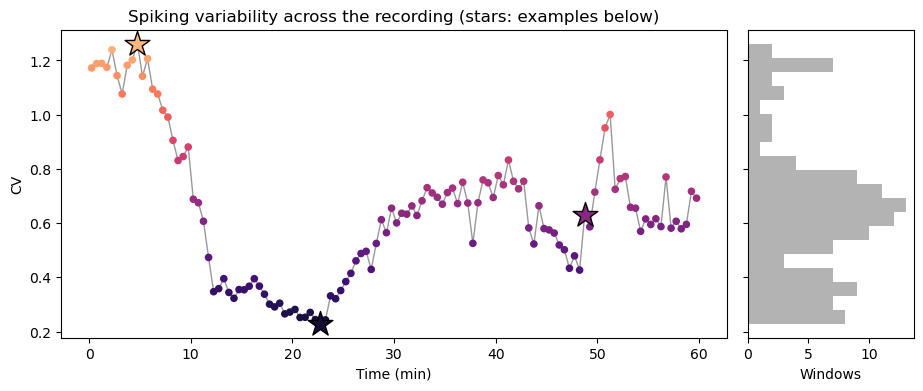

In [1]:
import prg_toolbox as prg
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap, Normalize

# Download the recording (only the first time) and load it as a (units, time bins) binary array
data_path = prg.datasets.get_long_recording()
data = prg.tools.load_data(data_path)

binsize_ms = 50
window_ms = 30_000  # 30 s windows
print(f"{data.shape[0]} units, {data.shape[1] * binsize_ms / 60_000:.0f} min of recording")

# Split the recording into consecutive 30 s windows. run_PRG uses this same function
# internally, so these windows match the PRG results we will compute later
windows = prg.tools.slice_by_time_window(
    data, window_duration_ms=window_ms, timeseries_binsize_ms=binsize_ms
)

# Population activity (active units per bin) and its CV in each window
population = np.array([w.sum(axis=0) for w in windows])
cv = population.std(axis=1) / population.mean(axis=1)
window_time_min = (np.arange(len(windows)) + 0.5) * window_ms / 60_000

# Example windows with the lowest, median and highest CV
examples = {"Low": np.argmin(cv), "Median": np.argsort(cv)[len(cv) // 2], "High": np.argmax(cv)}

# Color scale for CV used in all figures (magma without its pale-yellow end)
cv_cmap = LinearSegmentedColormap.from_list("cv", plt.cm.magma(np.linspace(0.1, 0.85, 256)))
cv_norm = Normalize(vmin=cv.min(), vmax=cv.max())

fig, (ax, ax_hist) = plt.subplots(
    1, 2, figsize=(11, 4), sharey=True, gridspec_kw={"width_ratios": [4, 1], "wspace": 0.05}
)
ax.plot(window_time_min, cv, color="0.6", lw=1, zorder=1)
ax.scatter(window_time_min, cv, c=cv, cmap=cv_cmap, norm=cv_norm, s=20, zorder=2)
for i in examples.values():
    ax.scatter(window_time_min[i], cv[i], marker="*", s=350, color=cv_cmap(cv_norm(cv[i])),
               edgecolor="k", zorder=3)
ax.set_xlabel("Time (min)")
ax.set_ylabel("CV")
ax.set_title("Spiking variability across the recording (stars: examples below)")
ax_hist.hist(cv, bins=20, orientation="horizontal", color="0.7")
ax_hist.set_xlabel("Windows")
plt.show()

#### What do low and high CV look like?

Below are the first 10 s of the three windows marked with stars, with their population activity underneath. In the low-CV window, units fire independently and the population activity fluctuates little around its mean. In the high-CV window, units fire together in bursts separated by silent periods.

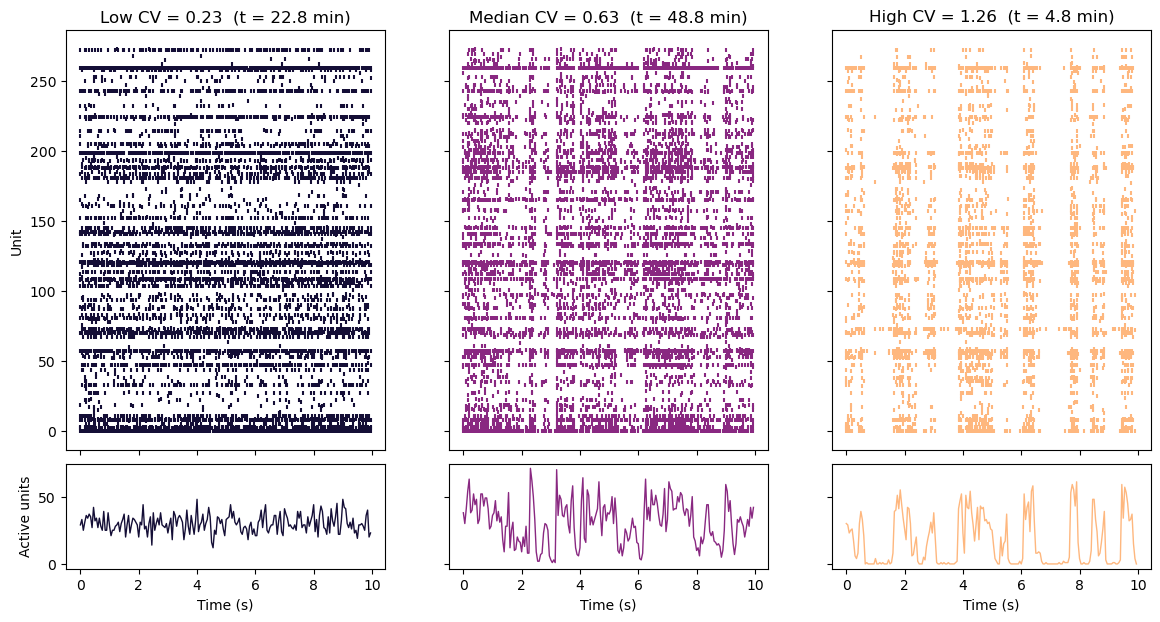

In [2]:
show_bins = int(10_000 / binsize_ms)  # first 10 s of each window
time_s = np.arange(show_bins) * binsize_ms / 1000

fig, axes = plt.subplots(
    2, 3, figsize=(14, 7), sharex=True, sharey="row", gridspec_kw={"height_ratios": [4, 1], "hspace": 0.05}
)
for col, (name, i) in enumerate(examples.items()):
    color = cv_cmap(cv_norm(cv[i]))
    units, bins = np.nonzero(windows[i][:, :show_bins])
    axes[0, col].scatter(time_s[bins], units, marker="|", s=6, color=color)
    axes[0, col].set_title(f"{name} CV = {cv[i]:.2f}  (t = {window_time_min[i]:.1f} min)")
    axes[1, col].plot(time_s, population[i, :show_bins], color=color, lw=1)
    axes[1, col].set_xlabel("Time (s)")
axes[0, 0].set_ylabel("Unit")
axes[1, 0].set_ylabel("Active units")
plt.show()

### Now run the PRG on each 30 s window

We don't need to slice the data ourselves: setting `time_slicing.window_duration_ms` makes `run_PRG` cut the recording into windows and run the coarse graining in each of them. The returned results hold the averages across windows, which we can plot with the built-in plotting functions.

Since this recording mixes very different cortical states, this average blends windows that, as we will see, behave quite differently.

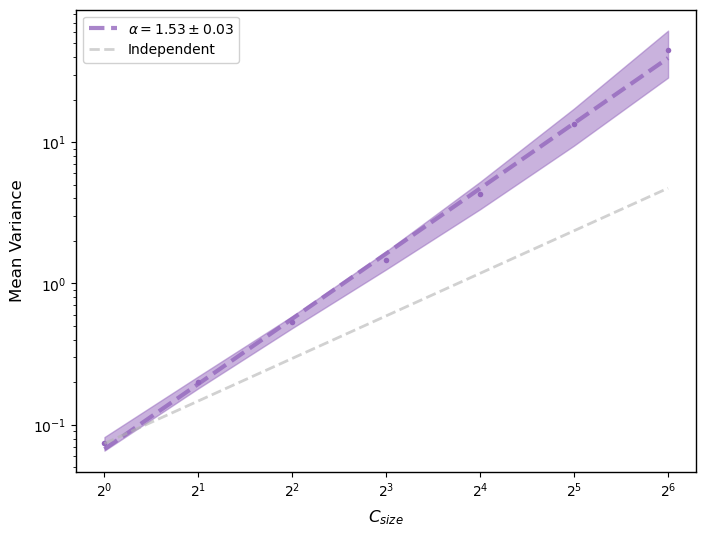

In [ ]:
prg_params = prg.config.AnalysisParams()
prg_params.observables = [prg.mean_variance, prg.activity_distribution]
prg_params.rg_steps = 6  # clusters of up to 2^6 = 64 units

# The data is already binary, in 50 ms bins, so we chose data_format="timeseries"
prg_params.loading.data_format = "timeseries"
prg_params.time_slicing.binary_binsize_ms = binsize_ms
prg_params.time_slicing.window_duration_ms = window_ms

# Units that are silent during a whole window are dropped from that window's coarse
# graining; 'silent' hides the warning that would otherwise be printed for each window
prg_params.verbose = "silent"

results = prg.run_PRG(data, user_params=prg_params)

# Mean variance averaged over all windows (shade: standard deviation across windows)
fig = plt.figure(figsize=(8, 6))
prg.plot.plot_mean_variance(results["mean_variance"], style_config=prg_params)
plt.show()

### Following the results over time

Besides the averages, the results keep each window's own outcome:
- `values` holds each window's observable (one row per window).
- `exponents_across_windows` holds each window's fitted exponent, with columns `[exponent, exponent_error, exponent_r2]`.

Rows follow the order of the windows, so they line up with the `cv` array we computed at the beginning.

Along with the mean variance exponent, we will follow how Gaussian the activity distribution of the coarse-grained variables is. For each window, we measure the Jensen-Shannon divergence (JSD) between the activity distribution of its largest clusters and a Gaussian with the same mean and standard deviation. The JSD is 0 for identical distributions and grows up to 1 as they become completely different.

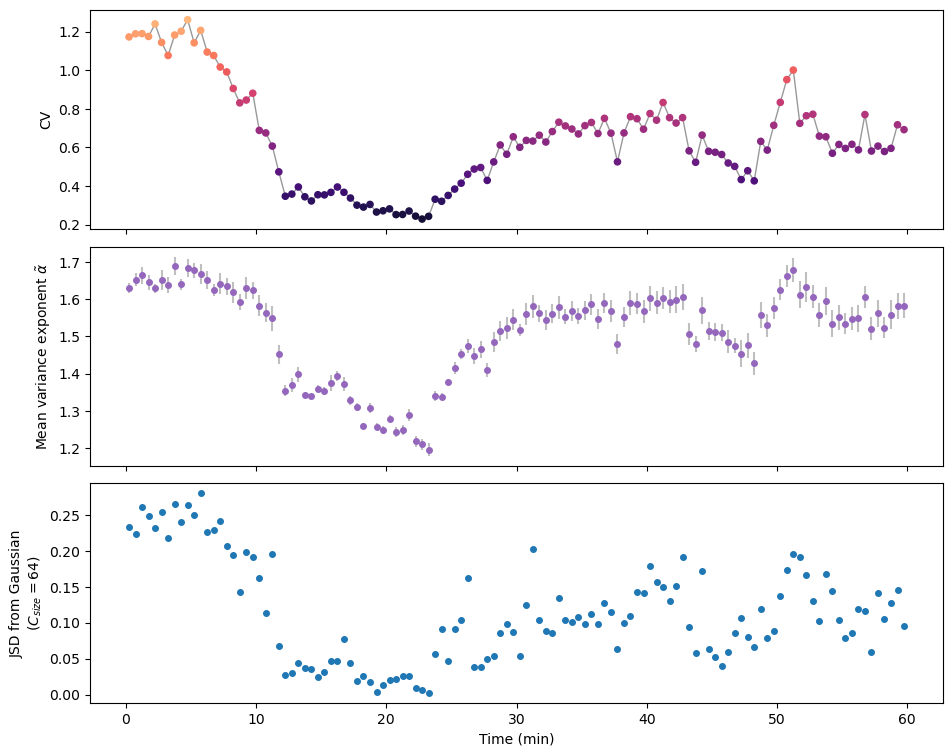

In [ ]:
from scipy.spatial.distance import jensenshannon


def matching_gaussian(p, x):
    # Gaussian with the same mean and standard deviation as p, as probabilities on the grid x
    p = p / p.sum()
    mean = np.sum(p * x)
    std = np.sqrt(np.sum(p * (x - mean) ** 2))
    gaussian = np.exp(-((x - mean) ** 2) / (2 * std**2))
    return gaussian / gaussian.sum()


dist = results["activity_distribution"].values[-1]  # largest clusters; one row per window
cluster_size = dist.shape[1] - 1
normalized_activity = np.arange(dist.shape[1]) / cluster_size  # same x axis as prg.plot.plot_activity_distribution

# jensenshannon returns the JS distance
jsd = np.array([
    jensenshannon(p / p.sum(), matching_gaussian(p, normalized_activity), base=2) ** 2 for p in dist
])
alpha = results["mean_variance"].exponents_across_windows  # columns: exponent, error, R²

fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True, gridspec_kw={"hspace": 0.08})
axes[0].plot(window_time_min, cv, color="0.6", lw=1, zorder=1)
axes[0].scatter(window_time_min, cv, c=cv, cmap=cv_cmap, norm=cv_norm, s=20, zorder=2)
axes[0].set_ylabel("CV")

axes[1].errorbar(window_time_min, alpha[:, 0], yerr=alpha[:, 1], fmt="o", ms=4, color="tab:purple", ecolor="0.75")
axes[1].set_ylabel(r"Mean variance exponent $\tilde{\alpha}$")

axes[2].plot(window_time_min, jsd, "o", ms=4, color="tab:blue")
axes[2].set_ylabel(f"JSD from Gaussian\n($C_{{size}} = {cluster_size}$)")
axes[2].set_xlabel("Time (min)")
plt.show()

#### Results as a function of CV

Parsing the windows by their CV instead of their time makes the relationship clearer. On the right, we also look at the activity distributions themselves: the average distribution of the 10 windows with the lowest CV and of the 10 windows with the highest CV (shades: standard deviation across those windows).

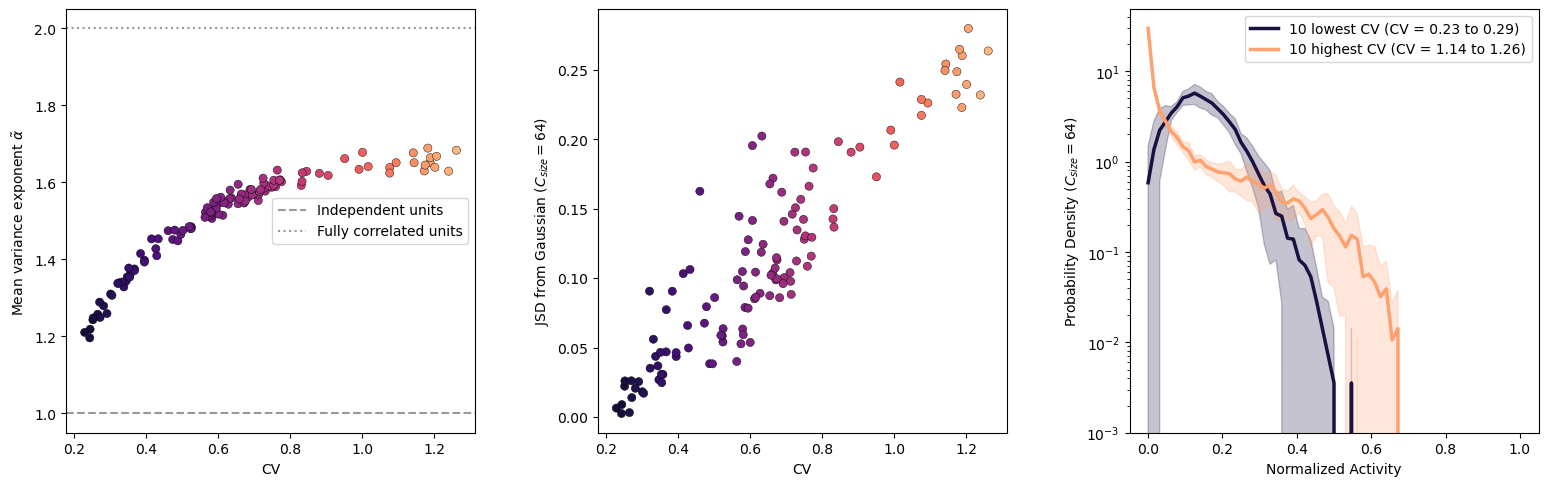

Spearman correlation with CV:  alpha 0.98,  JSD 0.90


In [5]:
from scipy.stats import spearmanr

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), gridspec_kw={"wspace": 0.3})

axes[0].scatter(cv, alpha[:, 0], c=cv, cmap=cv_cmap, norm=cv_norm, s=35, edgecolor="k", lw=0.3)
axes[0].axhline(1, ls="--", color="0.6", label="Independent units")
axes[0].axhline(2, ls=":", color="0.6", label="Fully correlated units")
axes[0].set_xlabel("CV")
axes[0].set_ylabel(r"Mean variance exponent $\tilde{\alpha}$")
axes[0].legend()

axes[1].scatter(cv, jsd, c=cv, cmap=cv_cmap, norm=cv_norm, s=35, edgecolor="k", lw=0.3)
axes[1].set_xlabel("CV")
axes[1].set_ylabel(f"JSD from Gaussian ($C_{{size}} = {cluster_size}$)")

lowest_cv, highest_cv = np.argsort(cv)[:10], np.argsort(cv)[-10:]
for name, idx in [("10 lowest CV", lowest_cv), ("10 highest CV", highest_cv)]:
    color = cv_cmap(cv_norm(cv[idx].mean()))
    mean, std = dist[idx].mean(axis=0), dist[idx].std(axis=0)
    axes[2].plot(normalized_activity, mean, color=color, lw=2.5,
                 label=f"{name} (CV = {cv[idx].min():.2f} to {cv[idx].max():.2f})")
    axes[2].fill_between(normalized_activity, mean - std, mean + std, color=color, alpha=0.25)
axes[2].set_yscale("log")
axes[2].set_ylim(bottom=1e-3)
axes[2].set_xlabel("Normalized Activity")
axes[2].set_ylabel(f"Probability Density ($C_{{size}} = {cluster_size}$)")
axes[2].legend()
plt.show()

print(f"Spearman correlation with CV:  alpha {spearmanr(cv, alpha[:, 0])[0]:.2f},  JSD {spearmanr(cv, jsd)[0]:.2f}")

Both results closely follow the spiking variability, over time and across windows. The mean variance exponent goes from $\tilde{\alpha} \approx 1.2$ in the most asynchronous windows, close to the value for independent units ($\tilde{\alpha} = 1$), up to $\tilde{\alpha} \approx 1.65$ once CV goes above about 0.8, where it levels off. At the same time, the activity distribution moves away from a Gaussian, with a JSD that grows steadily with CV.

For a deeper discussion, see [Castro et al. (2024)](https://doi.org/10.1103/PRXLife.2.023008).